# What drives a car's fuel efficiency, and how well can we predict it?

This notebook tells the story; the logic lives in tested modules under `src/fuel_efficiency/`.
It runs top to bottom with fixed seeds, so every number in the README can be reproduced with
`uv run jupyter nbconvert --execute --to notebook --inplace notebooks/fuel_efficiency.ipynb`.

**Data:** UCI Auto MPG, 398 cars from model years 1970 to 1982 (Quinlan, 1993, CC BY 4.0).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import statsmodels.formula.api as smf

from fuel_efficiency import style
from fuel_efficiency.clean import clean
from fuel_efficiency.data import read_raw
from fuel_efficiency.inference import coefficient_table, fit_ols, vif
from fuel_efficiency.model import FEATURES, SEED, TARGET, candidate_models, evaluate

warnings.filterwarnings("ignore", category=UserWarning)
style.apply()
pd.set_option("display.precision", 3)

## 1. Load and clean

The raw file stores six missing horsepower values as `?`, codes origin as 1, 2 and 3, and packs
make and model into one `name` field with misspellings such as "vw", "chevy" and "toyouta".
`clean()` decodes origin, fixes the makes, and adds metric weight and litres per 100 km.
Missing horsepower is left missing here: the prediction pipeline imputes it inside each training fold.

In [2]:
raw = read_raw()
df = clean(raw)
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])
df.head()

(398, 12)
horsepower    6
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,origin,name,make,year,weight_kg,l_per_100km
0,18.0,8,307.0,130.0,3504.0,12.0,USA,chevrolet chevelle malibu,chevrolet,1970,1589.388,13.067
1,15.0,8,350.0,165.0,3693.0,11.5,USA,buick skylark 320,buick,1970,1675.117,15.681
2,18.0,8,318.0,150.0,3436.0,11.0,USA,plymouth satellite,plymouth,1970,1558.543,13.067
3,16.0,8,304.0,150.0,3433.0,12.0,USA,amc rebel sst,amc,1970,1557.183,14.701
4,17.0,8,302.0,140.0,3449.0,10.5,USA,ford torino,ford,1970,1564.440,13.836


In [3]:
df["make"].value_counts().head(12)

make
ford          51
chevrolet     47
plymouth      31
amc           28
dodge         28
toyota        26
datsun        23
volkswagen    22
buick         17
pontiac       16
honda         13
mercury       12
Name: count, dtype: int64

## 2. Exploration

Heavier cars use more fuel, and cars got lighter and more efficient across the period.
Japanese and European cars were lighter on average, so origin and weight are tangled together.

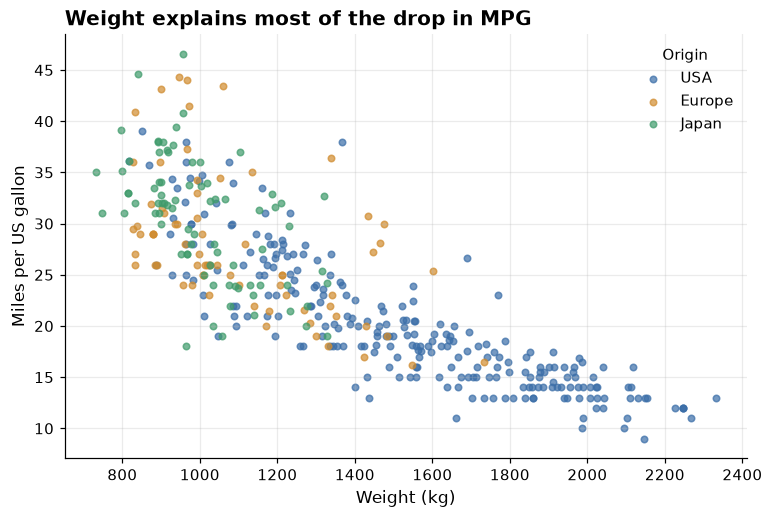

In [4]:
fig, ax = plt.subplots()
for origin, g in df.groupby("origin", observed=True):
    ax.scatter(g["weight_kg"], g["mpg"], s=18, alpha=0.7, label=origin, color=style.ORIGIN_COLOURS[origin])
ax.set(xlabel="Weight (kg)", ylabel="Miles per US gallon",
       title="Weight explains most of the drop in MPG")
ax.legend(title="Origin")
style.save(fig, "mpg_vs_weight");

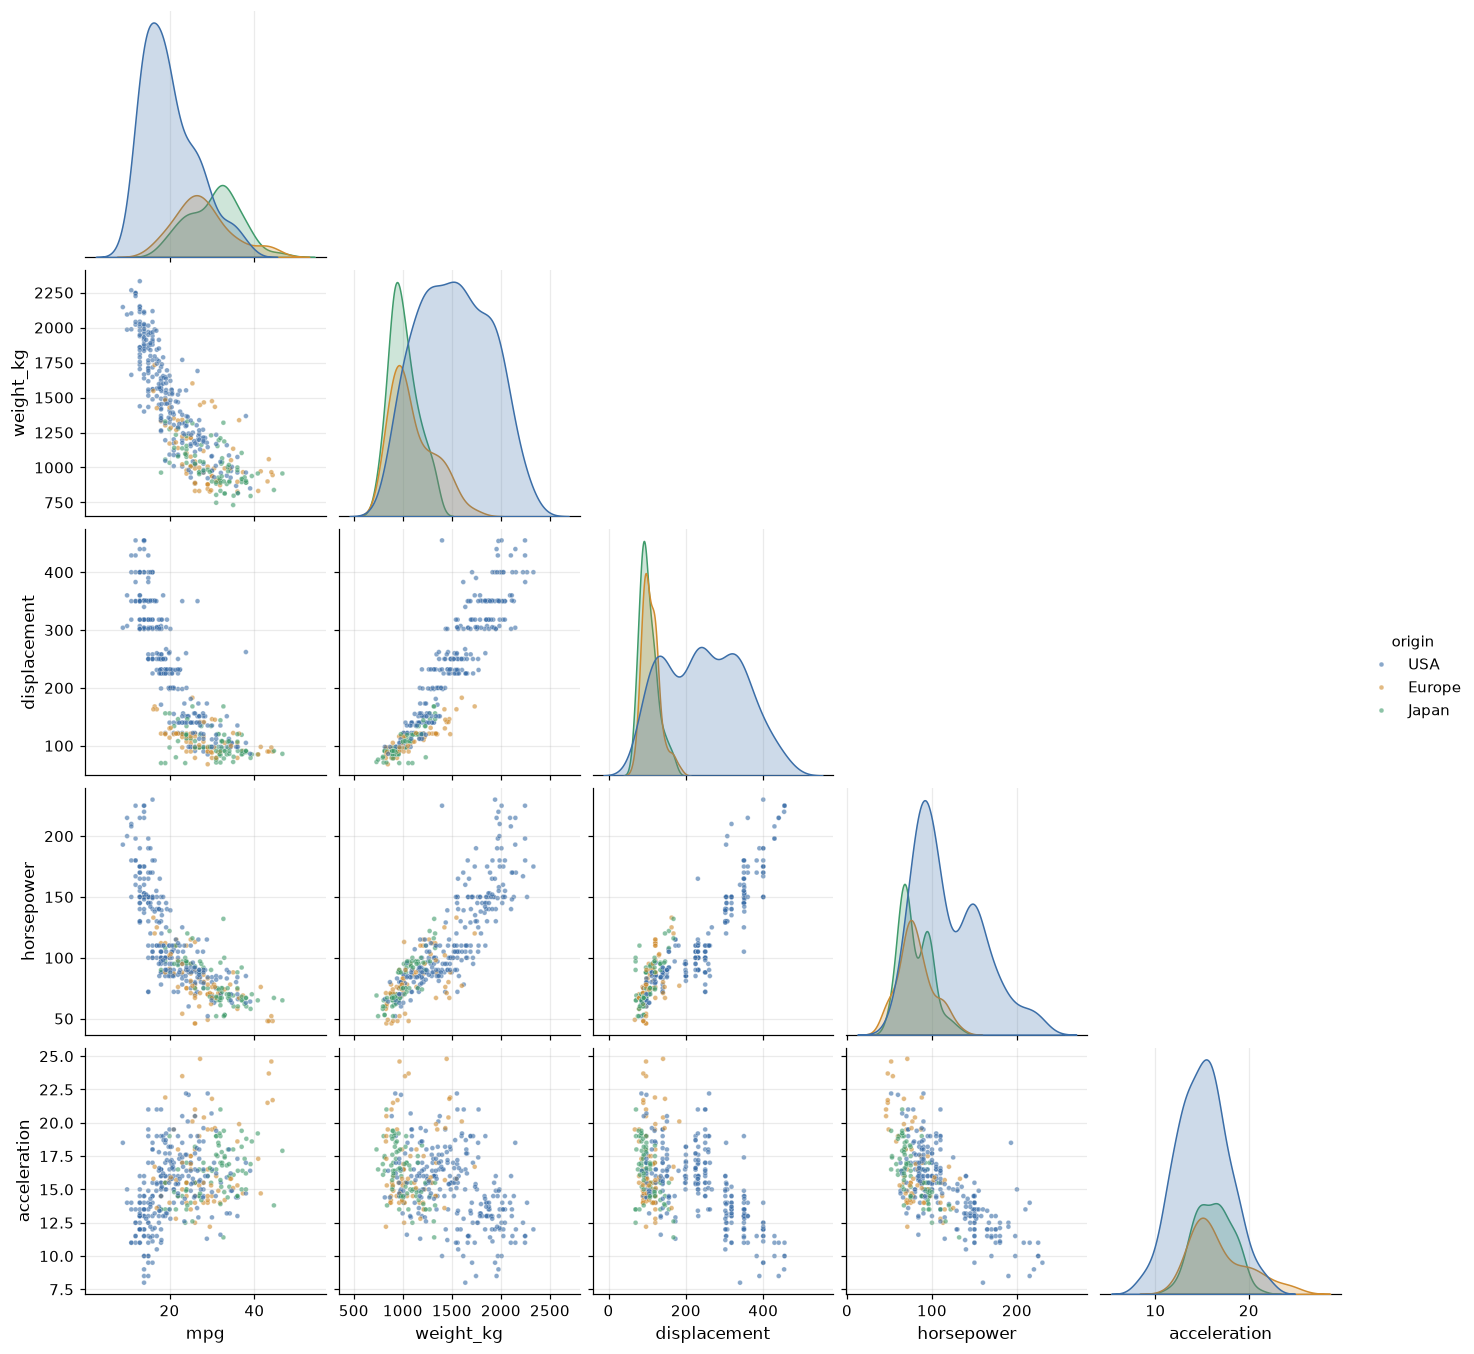

In [5]:
sns.pairplot(df[["mpg", "weight_kg", "displacement", "horsepower", "acceleration", "origin"]],
             hue="origin", palette=style.ORIGIN_COLOURS, plot_kws={"s": 10, "alpha": 0.6}, corner=True);

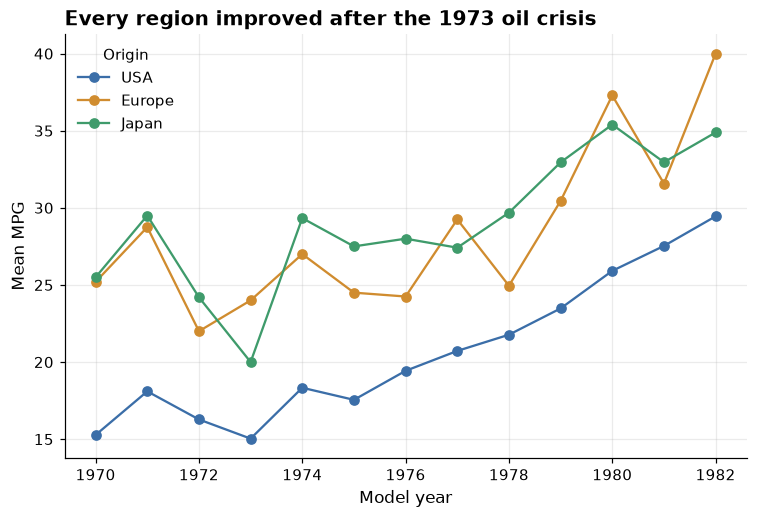

In [6]:
yearly = df.groupby(["year", "origin"], observed=True)["mpg"].mean().unstack()
fig, ax = plt.subplots()
for origin in yearly:
    ax.plot(yearly.index, yearly[origin], marker="o", label=origin, color=style.ORIGIN_COLOURS[origin])
ax.set(xlabel="Model year", ylabel="Mean MPG", title="Every region improved after the 1973 oil crisis")
ax.legend(title="Origin")
style.save(fig, "mpg_by_year");

## Part A: inference (why)

### Choosing the target

MPG is distance per unit of fuel. Fuel consumption (litres per 100 km) is its reciprocal and is what
physics ties to mass: moving twice the weight takes roughly twice the energy. If that holds, consumption
should be close to linear in weight while MPG curves. The comparison below checks it.

In [7]:
df["weight_100kg"] = df["weight_kg"] / 100
rows = []
for target in ["mpg", "l_per_100km"]:
    linear = smf.ols(f"{target} ~ weight_100kg", df).fit()
    curved = smf.ols(f"{target} ~ weight_100kg + I(weight_100kg**2)", df).fit()
    rows.append({"target": target, "R2 linear": linear.rsquared,
                 "R2 with squared term": curved.rsquared, "p of squared term": curved.pvalues.iloc[2]})
pd.DataFrame(rows).set_index("target")

,R2 linear,R2 with squared term,p of squared term
target,,,
mpg,0.692,0.715,3.188e-08
l_per_100km,0.784,0.787,1.377e-02


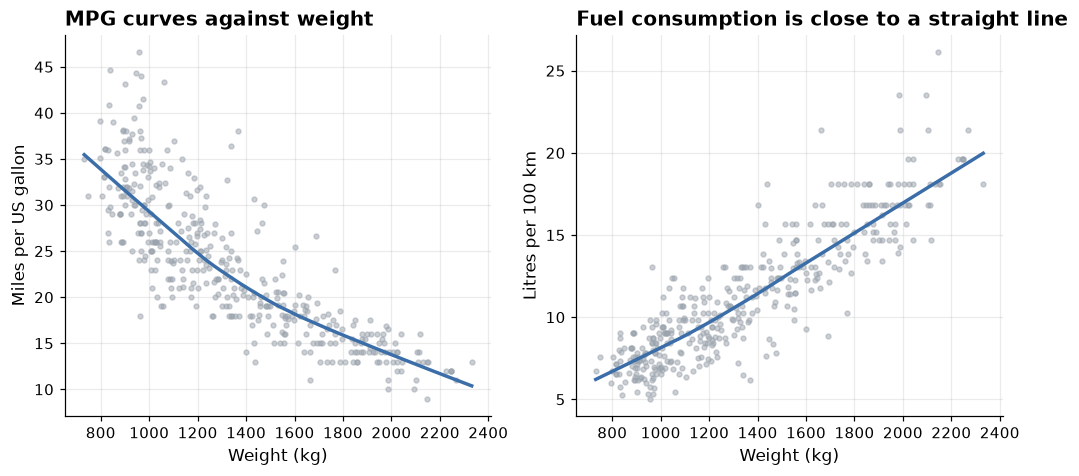

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (target, label) in zip(axes, [("mpg", "Miles per US gallon"), ("l_per_100km", "Litres per 100 km")], strict=True):
    sns.regplot(data=df, x="weight_kg", y=target, ax=ax, lowess=True,
                scatter_kws={"s": 10, "alpha": 0.5, "color": style.MUTED}, line_kws={"color": style.ACCENT})
    ax.set(xlabel="Weight (kg)", ylabel=label)
axes[0].set_title("MPG curves against weight")
axes[1].set_title("Fuel consumption is close to a straight line")
style.save(fig, "target_choice");

Litres per 100 km is much closer to linear (RÂ² 0.78 against 0.69, and the squared term adds almost nothing),
so Part A models consumption. MPG is still reported alongside for readers who think in MPG.

### Multicollinearity

Weight, displacement, cylinders and horsepower all measure "how big is the engine and car".

In [9]:
vif(df, ["weight_kg", "displacement", "cylinders", "horsepower", "acceleration", "year"]).to_frame()

,VIF
displacement,19.642
weight_kg,10.732
cylinders,10.633
horsepower,9.398
acceleration,2.626
year,1.245


In [10]:
df[["weight_kg", "displacement", "cylinders", "horsepower"]].corr()

,weight_kg,displacement,cylinders,horsepower
weight_kg,1.000,0.933,0.896,0.865
displacement,0.933,1.000,0.951,0.897
cylinders,0.896,0.951,1.000,0.843
horsepower,0.865,0.897,0.843,1.000


Displacement, cylinders and horsepower all have a VIF near or above 10 and correlate above 0.85 with weight.
Putting them in one regression would make each coefficient unstable and impossible to interpret on its own.
Weight is kept as the single size measure: it has the strongest link to consumption, it has no missing
values, and it is the quantity a buyer can compare directly. With weight, acceleration and year the VIFs fall
to about 1.3. Acceleration is then dropped as well because it is mostly a consequence of power to weight.

In [11]:
vif(df, ["weight_kg", "acceleration", "year"]).to_frame()

,VIF
weight_kg,1.269
acceleration,1.254
year,1.143


### Model and diagnostics

`l_per_100km ~ weight + year + origin`, with USA as the reference origin.

In [12]:
result = fit_ols(df, "l_per_100km ~ weight_100kg + year + C(origin)")
print(f"Breusch Pagan p value: {result.breusch_pagan_p:.2g}")
print(f"Cars with Cook's distance above 4/n: {result.n_influential}")
print(f"R squared: {result.model.rsquared:.3f}")
coefficient_table(result)

Breusch Pagan p value: 4.2e-05
Cars with Cook's distance above 4/n: 23
R squared: 0.876


,coef,ci_low,ci_high,p_value
Intercept,672.209,592.849,751.568,1.691e-47
C(origin)[T.Europe],-0.583,-0.988,-0.179,4.833e-03
C(origin)[T.Japan],-0.169,-0.505,0.167,3.225e-01
weight_100kg,0.774,0.725,0.823,8.489e-108
year,-0.340,-0.380,-0.300,1.562e-47


The Breusch Pagan test rejects constant variance, so `fit_ols` reports HC3 robust standard errors.
The coefficients are unchanged; only the confidence intervals widen.

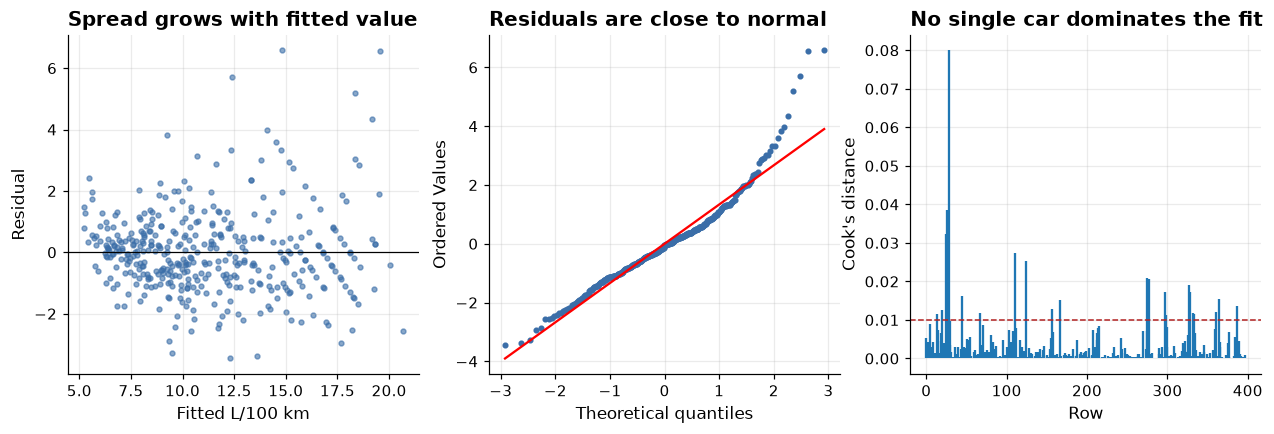

In [13]:
plain = smf.ols("l_per_100km ~ weight_100kg + year + C(origin)", df).fit()
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(plain.fittedvalues, plain.resid, s=10, alpha=0.6, color=style.ACCENT)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(xlabel="Fitted L/100 km", ylabel="Residual", title="Spread grows with fitted value")
stats.probplot(plain.resid, plot=axes[1])
axes[1].get_lines()[0].set(markersize=3, color=style.ACCENT)
axes[1].set_title("Residuals are close to normal")
cooks = result.cooks_distance
axes[2].stem(cooks.index, cooks.values, markerfmt=" ", basefmt=" ")
axes[2].axhline(4 / len(cooks), color="firebrick", ls="--", lw=1)
axes[2].set(xlabel="Row", ylabel="Cook's distance", title="No single car dominates the fit")
style.save(fig, "ols_diagnostics");

In [14]:
top = cooks.sort_values(ascending=False).head(5).index
df.loc[top, ["name", "year", "origin", "weight_kg", "mpg", "l_per_100km"]].assign(cooks=cooks[top])

,name,year,origin,weight_kg,mpg,l_per_100km,cooks
28,hi 1200d,1970,USA,2146.399,9.0,26.135,0.080
26,chevy c20,1970,USA,1984.920,10.0,23.521,0.039
25,ford f250,1970,USA,2093.329,10.0,23.521,0.032
111,maxda rx3,1973,Japan,963.430,18.0,13.067,0.027
124,oldsmobile omega,1973,USA,1661.962,11.0,21.383,0.025


In [15]:
without = smf.ols("l_per_100km ~ weight_100kg + year + C(origin)", df.drop(index=cooks[cooks > 4 / len(cooks)].index)).fit()
pd.DataFrame({"all cars": plain.params, "influential removed": without.params})

,all cars,influential removed
Intercept,672.209,578.597
C(origin)[T.Europe],-0.583,-0.410
C(origin)[T.Japan],-0.169,-0.168
weight_100kg,0.774,0.776
year,-0.340,-0.292


Removing the influential cars (mostly heavy 1970 trucks such as the Ford F250) leaves the weight coefficient unchanged at 0.77 and moves the year coefficient only from 0.34 to 0.29, so they are kept in.

### In plain English

In [16]:
coefs = coefficient_table(result)
w = coefs.loc["weight_100kg"]
y = coefs.loc["year"]
mpg_fit = fit_ols(df, "mpg ~ weight_100kg + year + C(origin)")
mw = coefficient_table(mpg_fit).loc["weight_100kg"]
print(f"Each extra 100 kg is associated with {w.coef:.2f} more litres per 100 km "
      f"(95% CI {w.ci_low:.2f} to {w.ci_high:.2f}), holding model year and origin constant.")
print(f"In MPG terms that is about {-mw.coef:.1f} fewer MPG per 100 kg (95% CI {-mw.ci_high:.1f} to {-mw.ci_low:.1f}).")
print(f"Each newer model year is associated with {-y.coef:.2f} fewer litres per 100 km at the same weight.")

Each extra 100 kg is associated with 0.77 more litres per 100 km (95% CI 0.72 to 0.82), holding model year and origin constant.
In MPG terms that is about 1.3 fewer MPG per 100 kg (95% CI 1.2 to 1.4).
Each newer model year is associated with 0.34 fewer litres per 100 km at the same weight.


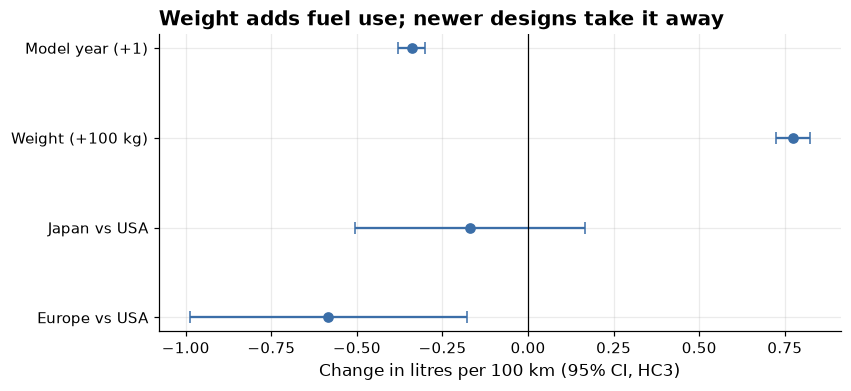

In [17]:
plot = coefs.drop(index="Intercept")
labels = {"weight_100kg": "Weight (+100 kg)", "year": "Model year (+1)",
          "C(origin)[T.Europe]": "Europe vs USA", "C(origin)[T.Japan]": "Japan vs USA"}
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(plot["coef"], range(len(plot)), xerr=[plot["coef"] - plot["ci_low"], plot["ci_high"] - plot["coef"]],
            fmt="o", color=style.ACCENT, capsize=4)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(plot)), [labels[i] for i in plot.index])
ax.set(xlabel="Change in litres per 100 km (95% CI, HC3)",
       title="Weight adds fuel use; newer designs take it away")
style.save(fig, "coefficients");

Once weight and year are held constant, origin matters far less than the raw averages suggest.
Japanese cars look efficient mainly because they were light.

## Part B: prediction (how well)

Target is MPG, the quantity a reader would want predicted. Every model is a full sklearn `Pipeline`
(median imputation, scaling, one hot origin), so nothing is learned from the test fold.
Ridge, Lasso and gradient boosting are tuned by an inner 5 fold grid search inside each outer fold
(nested cross validation). The outer loop is 5 fold repeated 3 times, giving 15 test scores per model.

In [18]:
X, y = df[FEATURES], df[TARGET]
scores = evaluate(candidate_models(), X, y)
scores

,mae_mean,mae_sd,rmse_mean,rmse_sd
model,,,,
Gradient boosting,2.043,0.259,2.849,0.361
Lasso,2.550,0.200,3.351,0.323
Ridge,2.553,0.201,3.356,0.328
Linear regression,2.565,0.199,3.336,0.301
Baseline (mean),6.544,0.393,7.806,0.489


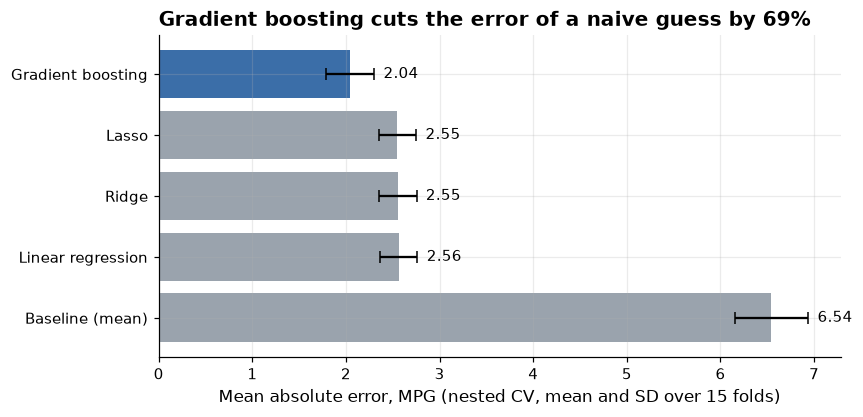

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = scores.sort_values("mae_mean", ascending=False)
colours = [style.ACCENT if m == order.index[-1] else style.MUTED for m in order.index]
ax.barh(order.index, order["mae_mean"], xerr=order["mae_sd"], color=colours, capsize=4)
for i, v in enumerate(order["mae_mean"]):
    ax.text(v + order["mae_sd"].iloc[i] + 0.1, i, f"{v:.2f}", va="center")
best = scores.iloc[0]
base = scores.loc["Baseline (mean)"]
ax.set(xlabel="Mean absolute error, MPG (nested CV, mean and SD over 15 folds)",
       title=f"Gradient boosting cuts the error of a naive guess by {1 - best.mae_mean / base.mae_mean:.0%}")
style.save(fig, "model_comparison");

### Explaining the best model

The tuned gradient boosting model is refitted on all cars purely to explain it. SHAP values show how much
each feature pushes a prediction above or below the average.

In [20]:
import shap

gbm = candidate_models()["Gradient boosting"].fit(X, y).best_estimator_
prep, booster = gbm.named_steps["prep"], gbm.named_steps["model"]
Xt = pd.DataFrame(prep.transform(X), columns=[c.split("__")[1] for c in prep.get_feature_names_out()], index=X.index)
explainer = shap.TreeExplainer(booster)
shap_values = explainer(Xt)
importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=Xt.columns).sort_values(ascending=False)
importance.to_frame("mean |SHAP| (MPG)")

,mean |SHAP| (MPG)
weight_kg,2.767
year,2.354
displacement,1.501
cylinders,1.014
horsepower,0.890
acceleration,0.379
origin_USA,0.325
origin_Japan,0.025


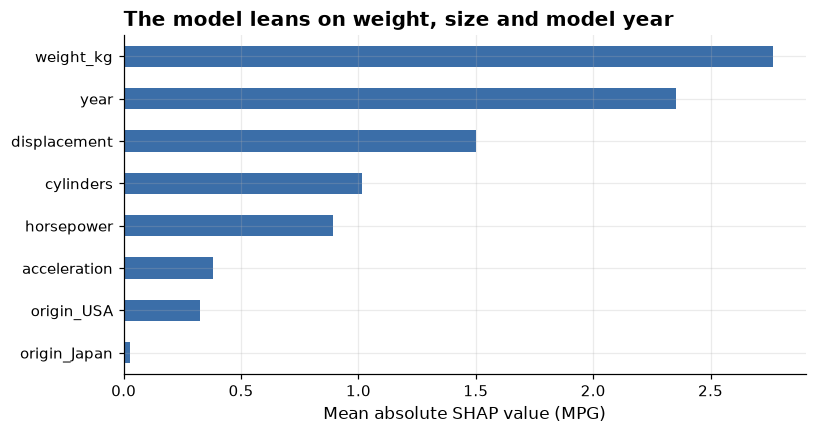

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
importance.sort_values().plot.barh(ax=ax, color=style.ACCENT)
ax.set(xlabel="Mean absolute SHAP value (MPG)", title="The model leans on weight, size and model year")
style.save(fig, "shap_importance");

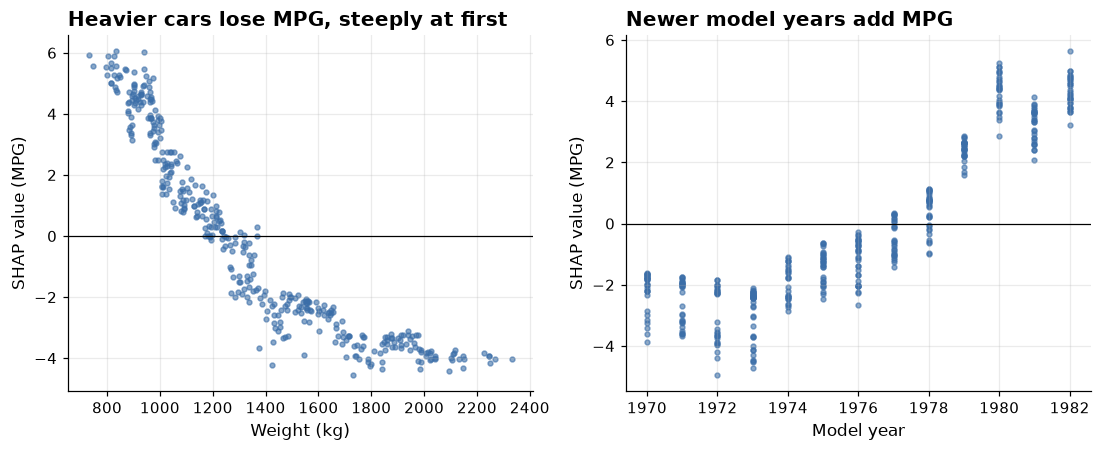

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, feat, label in [(axes[0], "weight_kg", "Weight (kg)"), (axes[1], "year", "Model year")]:
    ax.scatter(X[feat], shap_values[:, feat].values, s=10, alpha=0.6, color=style.ACCENT)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xlabel=label, ylabel="SHAP value (MPG)")
axes[0].set_title("Heavier cars lose MPG, steeply at first")
axes[1].set_title("Newer model years add MPG")
style.save(fig, "shap_dependence");

This agrees with Part A: weight and model year carry the signal, and once they are known, origin adds little.
Displacement, horsepower and cylinders share credit with weight because they measure the same thing; the
model does not care about collinearity, but it also means their individual SHAP values should not be read as
separate causes. The curved weight effect matches the target choice in Part A: weight lowers MPG fastest for
light cars, which is exactly the reciprocal shape.

### Where does the model fail?

Out of fold predictions (each car predicted by a model that never saw it), grouped by origin and year.

In [23]:
from sklearn.model_selection import KFold, cross_val_predict

oof = cross_val_predict(candidate_models()["Gradient boosting"], X, y, cv=KFold(5, shuffle=True, random_state=SEED))
df["residual"] = y - oof
by_origin = df.groupby("origin", observed=True)["residual"].agg(["mean", lambda r: r.abs().mean(), "count"])
by_origin.columns = ["mean residual", "MAE", "cars"]
by_origin

,mean residual,MAE,cars
origin,,,
USA,-0.030,1.655,249
Europe,0.322,2.818,70
Japan,-0.014,2.745,79


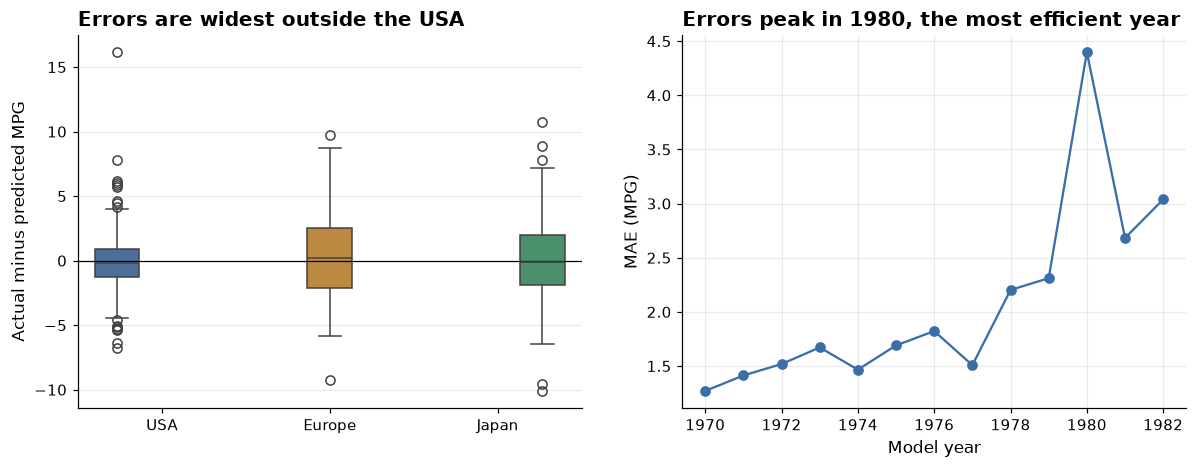

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sns.boxplot(data=df, x="origin", y="residual", hue="origin", palette=style.ORIGIN_COLOURS, ax=axes[0], legend=False)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(xlabel="", ylabel="Actual minus predicted MPG", title="Errors are widest outside the USA")
yearly_mae = df.groupby("year")["residual"].apply(lambda r: r.abs().mean())
axes[1].plot(yearly_mae.index, yearly_mae.values, marker="o", color=style.ACCENT)
axes[1].set(xlabel="Model year", ylabel="MAE (MPG)", title="Errors peak in 1980, the most efficient year")
style.save(fig, "residuals");

In [25]:
df.reindex(df["residual"].abs().sort_values(ascending=False).index)[["name", "year", "origin", "weight_kg", "mpg", "residual"]].head(8)

,name,year,origin,weight_kg,mpg,residual
387,oldsmobile cutlass ciera (diesel),1982,USA,1367.581,38.0,16.157
333,datsun 280-zx,1980,Japan,1319.954,32.7,10.735
111,maxda rx3,1973,Japan,963.430,18.0,-10.095
244,volkswagen rabbit custom diesel,1978,Europe,900.381,43.1,9.758
334,mazda rx-7 gs,1980,Japan,1097.694,23.7,-9.519
332,vokswagen rabbit,1980,Europe,836.878,29.8,-9.221
329,honda civic 1500 gl,1980,Japan,839.146,44.6,8.852
394,vw pickup,1982,Europe,966.152,44.0,8.760


The largest misses have engines the features cannot describe. Diesels (the Oldsmobile Cutlass Ciera diesel,
the VW Rabbit diesel) beat their prediction by 10 to 16 MPG, and Mazda's rotary engines (RX3, RX7) fall short by
about 10. Neither fuel type nor engine type is recorded in the data. Error also grows with
MPG itself, the same widening spread the Breusch Pagan test found in Part A.

## Summary

* **Why:** weight is the main driver. Each extra 100 kg adds about 0.77 L/100 km, and newer model years used
  less fuel at the same weight. Origin adds little once weight is known.
* **How well:** tuned gradient boosting predicts MPG to within about 2 MPG on average in nested cross
  validation, against about 6.5 for a naive mean, and beats linear models by about half an MPG.